## import thư viện

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [48]:
df = pd.read_csv(r'data/train.csv')
test = pd.read_csv(r'data/test.csv')

## PHẦN 1:Tổng quan dữ liệu

- 2930 giao dịch bán nhà ở Ames, Iowa (2006-2010)
- 80 biến: 20 liên tục, 14 rời rạc, 23 định danh, 23 thứ tự
- Biến mục tiêu: `SalePrice`
- `PID` chỉ là mã thửa đất, không có ý nghĩa dự báo nên bỏ khi phân tích


Dữ liệu là giao dịch bán nhà ở Ames, Iowa (2006-2010), theo paper của De Cock (2011) có 2930 giao dịch và 80 biến. File đang dùng là `train.csv` (bản Kaggle House Prices, chia từ cùng bộ dữ liệu này), nên chỉ có:

- 1460 dòng, 81 cột (gồm `Id` và biến mục tiêu `SalePrice`)
- 38 cột số, 43 cột chữ
- `Id` chỉ là số thứ tự, không dùng để dự báo

In [49]:
df.shape

(1460, 81)

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### 1.1.Phân loại biến

- **Liên tục:** chủ yếu là các loại diện tích (lô đất, tầng hầm, diện tích sinh hoạt, hiên...)
- **Rời rạc:** số phòng ngủ, phòng tắm, bếp, sức chứa gara, năm xây/sửa
- **Định danh:** loại nhà, vật liệu, khu vực... trong đó `Neighborhood` có 28 mức, nhiều nhất
- **Thứ tự:** các thang chất lượng (chất lượng tổng thể, bếp, tầng hầm...)

In [51]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [52]:
df.select_dtypes(exclude='number').describe().T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### 1.2.Nhận xét ban đầu

- Dữ liệu 1460 x 81, nhiều cột thiếu (19 cột), nhiều cột bị thiếu đến 99% dữ liệu phải xem xét lại Dataset liệu có phải missing thật hay là thuộc tính của căn nhà là không có (không sở hữu) những đặc trưng này


In [53]:
skew = df.select_dtypes('number').skew().sort_values(ascending=False)
print("SalePrice skew:", df['SalePrice'].skew())
skew.head(10)

SalePrice skew: 1.8828757597682129


MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
dtype: float64

- `SalePrice` lệch phải (skew = 1), trung bình lớn hơn trung vị
- Các cột lệch mạnh nhất: MiscVal  (nhiều cột diện tích có phần lớn giá trị bằng 0, như `PoolArea`, `MiscVal`, `3SsnPorch`)

### 1.3.Ghi chú từ paper

- Tác giả khuyên loại nhà có `GrLivArea` > 4000 sq ft (5 điểm bất thường)
- Biến thứ tự và biến rời rạc có thể cho hệ số không đơn điệu khi mã hóa thành biến giả
- Hai ý này để dành cho phần outliers và phân tích đa biến

## PHẦN 2:PHÂN TÍCH ĐƠN BIẾN

Mục tiêu của phân tích đơn biến là khảo sát từng biến độc lập riêng lẻ để:
- hiểu phân bố của dữ liệu;
- nhận diện biến lệch phải/lệch trái;
- phát hiện giá trị 0, giá trị bất thường và ngoại lệ sơ bộ;
- với biến phân loại, xem tần suất xuất hiện của từng nhóm;
- xác định những biến cần chú ý trước khi thực hiện phân tích đa biến.

Phân tích được chia thành:
1. Biến số (`numeric`)
2. Biến phân loại (`categorical`)
3. Biến mục tiêu `SalePrice`

In [54]:
# Tách biến số và biến phân loại
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

# Không xem Id/PID là biến phân tích
numeric_analysis_cols = [c for c in numeric_cols if c not in ['Id', 'PID']]

print("Số biến số dùng để phân tích:", len(numeric_analysis_cols))
print("Số biến phân loại:", len(categorical_cols))

Số biến số dùng để phân tích: 37
Số biến phân loại: 43


### 2.1. Phân tích đơn biến đối với biến số

Trước tiên xem các đại lượng cơ bản: min, max, trung bình, trung vị, độ lệch chuẩn và độ lệch phân phối (`skewness`).

In [55]:
numeric_summary = df[numeric_analysis_cols].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).T

numeric_summary['skewness'] = df[numeric_analysis_cols].skew()
numeric_summary = numeric_summary.sort_values('skewness', ascending=False)

numeric_summary.head(20)

,count,mean,median,std,min,max,skewness
MiscVal,1460.0,43.489041,0.0,496.123024,0.0,15500.0,24.476794
PoolArea,1460.0,2.758904,0.0,40.177307,0.0,738.0,14.828374
LotArea,1460.0,10516.828082,9478.5,9981.264932,1300.0,215245.0,12.207688
3SsnPorch,1460.0,3.409589,0.0,29.317331,0.0,508.0,10.304342
LowQualFinSF,1460.0,5.844521,0.0,48.623081,0.0,572.0,9.011341
KitchenAbvGr,1460.0,1.046575,1.0,0.220338,0.0,3.0,4.488397
BsmtFinSF2,1460.0,46.549315,0.0,161.319273,0.0,1474.0,4.255261
ScreenPorch,1460.0,15.060959,0.0,55.757415,0.0,480.0,4.122214
BsmtHalfBath,1460.0,0.057534,0.0,0.238753,0.0,2.0,4.103403
EnclosedPorch,1460.0,21.954110,0.0,61.119149,0.0,552.0,3.089872


### Nhận xét

- `mean` và `median` giúp so sánh mức độ đối xứng của phân phối.
- Nếu `mean > median` đáng kể, biến thường có xu hướng lệch phải.
- `skewness > 0` cho thấy phân phối lệch phải; `skewness < 0` cho thấy lệch trái.
- Những biến có độ lệch lớn cần được chú ý vì có thể chứa nhiều giá trị rất lớn hoặc tập trung nhiều ở một vùng giá trị.

### 2.2. Phân phối của `SalePrice`

`SalePrice` là biến mục tiêu nên được khảo sát riêng trước khi phân tích mối quan hệ với các biến khác.

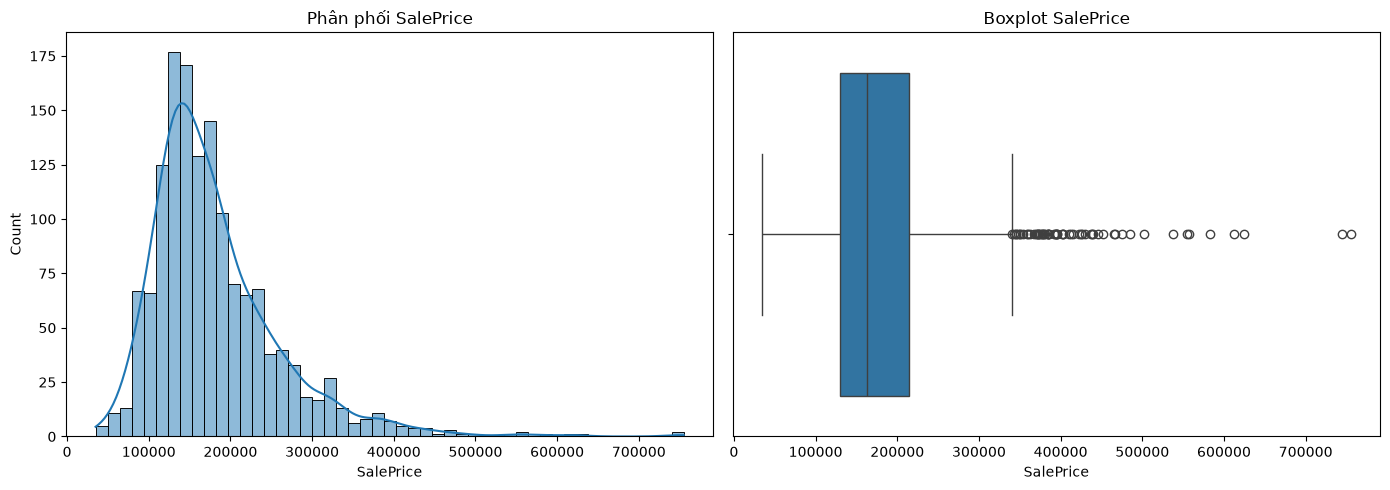

Mean: 180921.19589041095
Median: 163000.0
Skewness: 1.8828757597682129


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Phân phối SalePrice')
axes[0].set_xlabel('SalePrice')

sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('Boxplot SalePrice')
axes[1].set_xlabel('SalePrice')

plt.tight_layout()
plt.show()

print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Skewness:", df['SalePrice'].skew())

### Nhận xét về `SalePrice`

- Quan sát histogram để đánh giá hình dạng phân phối.
- So sánh mean và median để nhận biết độ lệch.
- Boxplot giúp quan sát các giá trị nằm xa phần lớn dữ liệu.
- Theo phần tổng quan trước đó, `SalePrice` có xu hướng **lệch phải**, do đó một số căn nhà có giá bán rất cao kéo dài đuôi phân phối về phía phải.

### 2.3. Phân tích các biến số quan trọng

Một số biến số có ý nghĩa trực tiếp đối với quy mô và đặc điểm căn nhà, ví dụ:
- `GrLivArea`: diện tích sinh hoạt trên mặt đất;
- `TotalBsmtSF`: tổng diện tích tầng hầm;
- `1stFlrSF`: diện tích tầng 1;
- `GarageArea`: diện tích gara;
- `YearBuilt`: năm xây dựng;
- `OverallQual`: chất lượng tổng thể.

Dùng histogram và boxplot để khảo sát phân phối của các biến này.

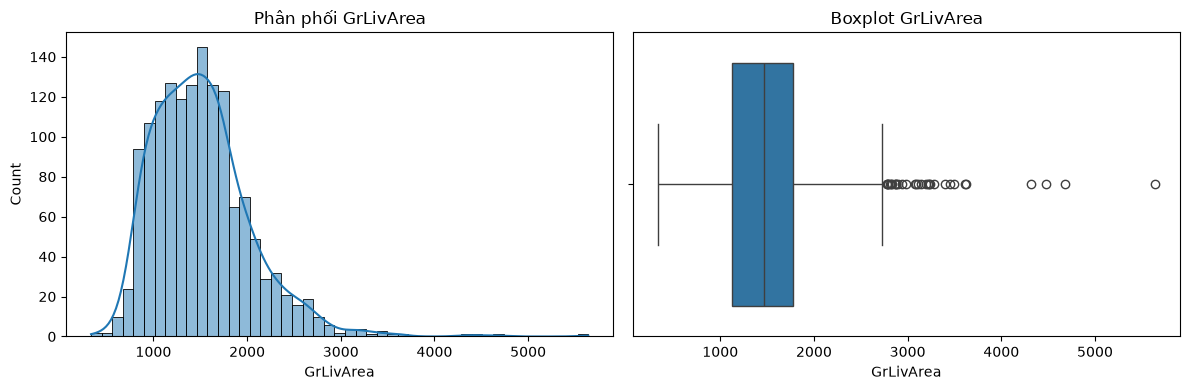

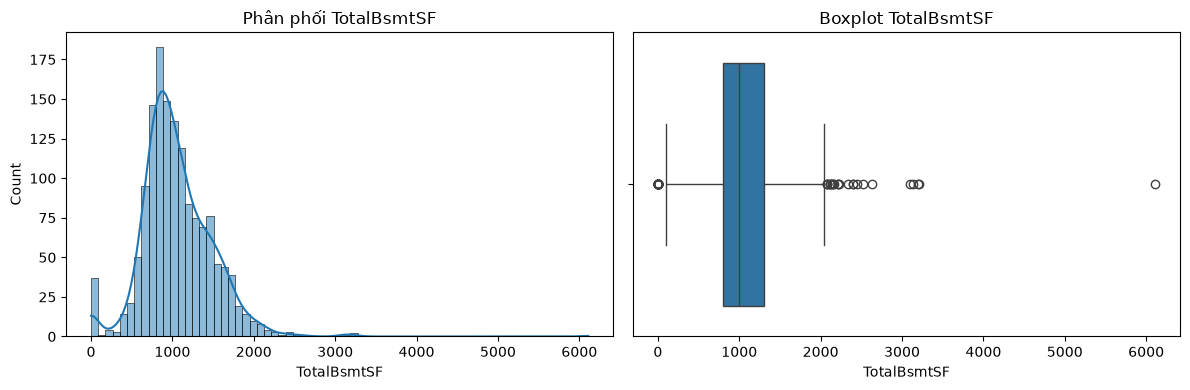

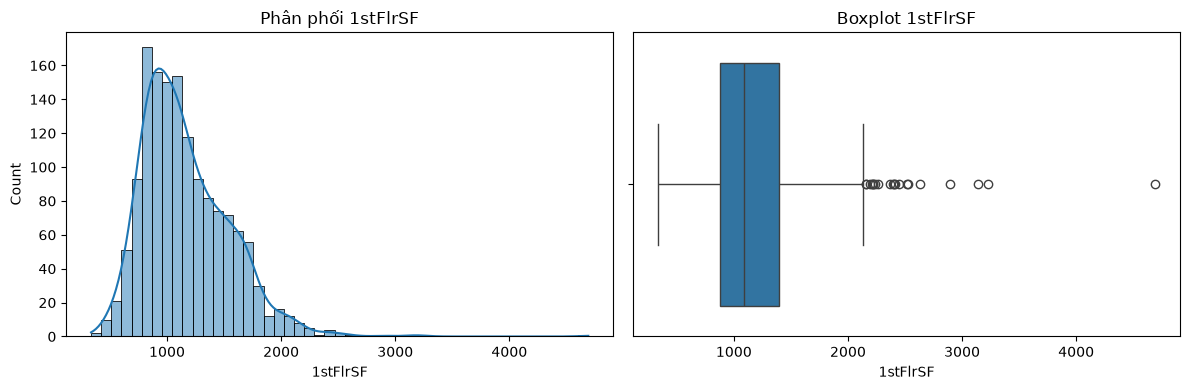

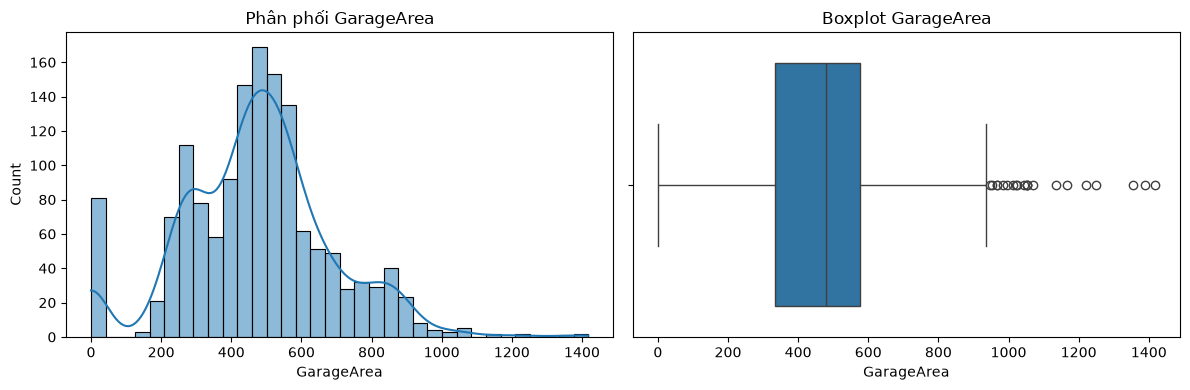

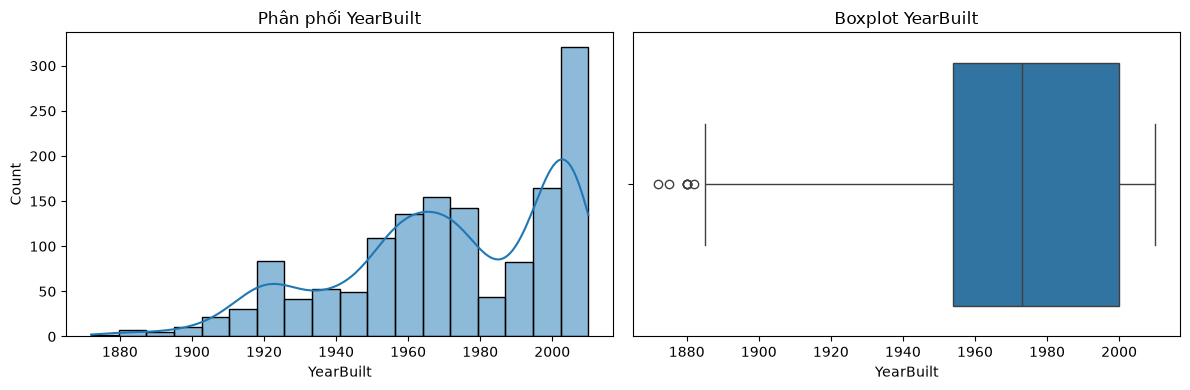

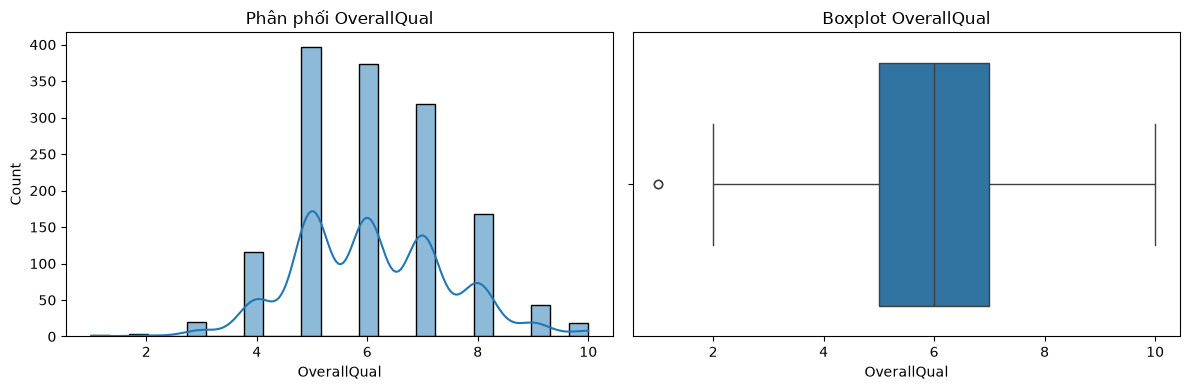

In [57]:
important_numeric = [
    c for c in [
        'GrLivArea', 'TotalBsmtSF', '1stFlrSF',
        'GarageArea', 'YearBuilt', 'OverallQual'
    ] if c in df.columns
]

for col in important_numeric:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f'Phân phối {col}')

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'Boxplot {col}')

    plt.tight_layout()
    plt.show()

### 2.4. Phân tích đơn biến đối với biến phân loại

Với biến phân loại, thay vì tính trung bình, ta quan sát số lượng và tỷ lệ của từng nhóm. Điều này giúp phát hiện:
- nhóm chiếm đa số;
- nhóm rất hiếm;
- biến có quá nhiều mức;
- nhóm có tần suất bằng 0 hoặc gần 0.

In [58]:
# Bảng tần suất của các biến phân loại
for col in categorical_cols:
    print(f'\n===== {col} =====')
    freq = df[col].value_counts(dropna=False)
    print(freq.head(15))
    print("Số mức:", df[col].nunique(dropna=False))


===== MSZoning =====
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64
Số mức: 5

===== Street =====
Street
Pave    1454
Grvl       6
Name: count, dtype: int64
Số mức: 2

===== Alley =====
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64
Số mức: 3

===== LotShape =====
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64
Số mức: 4

===== LandContour =====
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64
Số mức: 4

===== Utilities =====
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64
Số mức: 2

===== LotConfig =====
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64
Số mức: 5

===== LandSlope =====
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64
Số mức: 3

===== Neighborhood =====
Neighborhood
NAmes      225
CollgCr    150
OldTown   

### 2.5. Trực quan hóa một số biến phân loại quan trọng

Có thể dùng biểu đồ cột cho các biến có số lượng mức vừa phải. `Neighborhood`, `HouseStyle`, `BldgType`, `KitchenQual` và `ExterQual` là những biến có thể khảo sát trước.

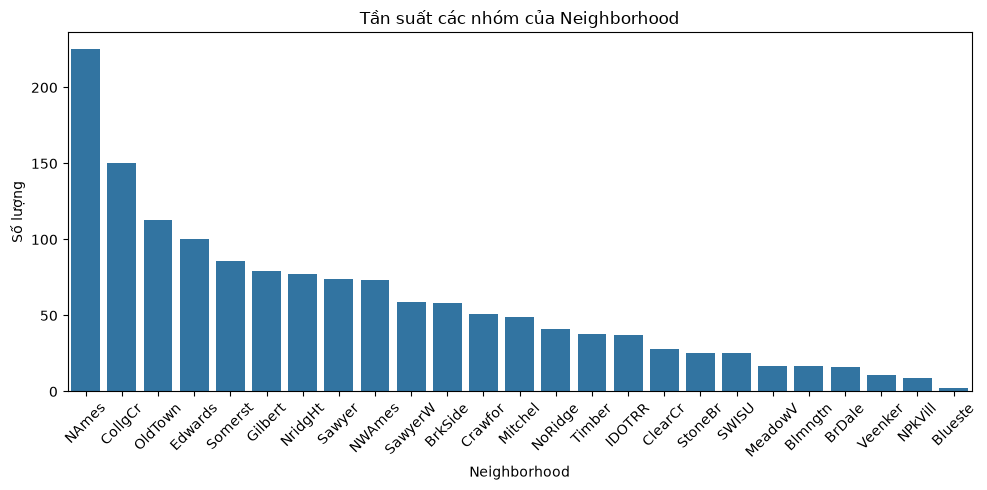

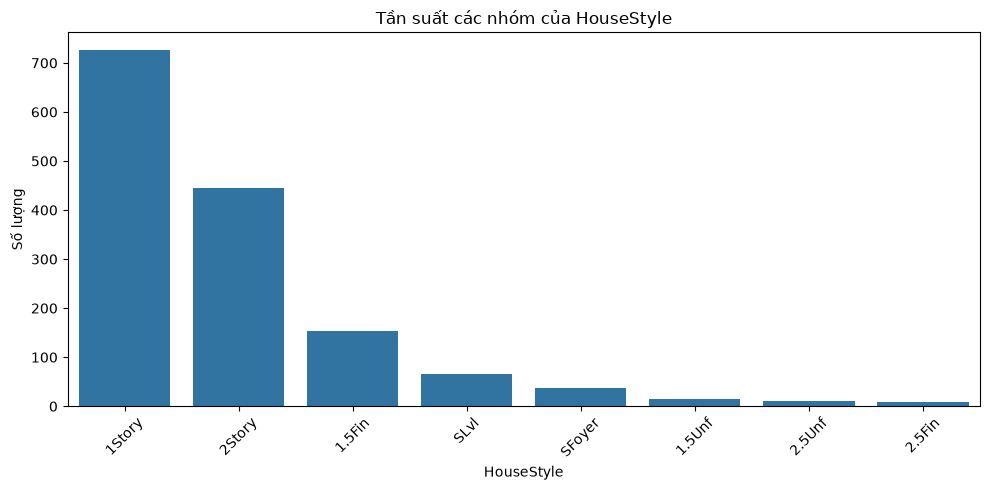

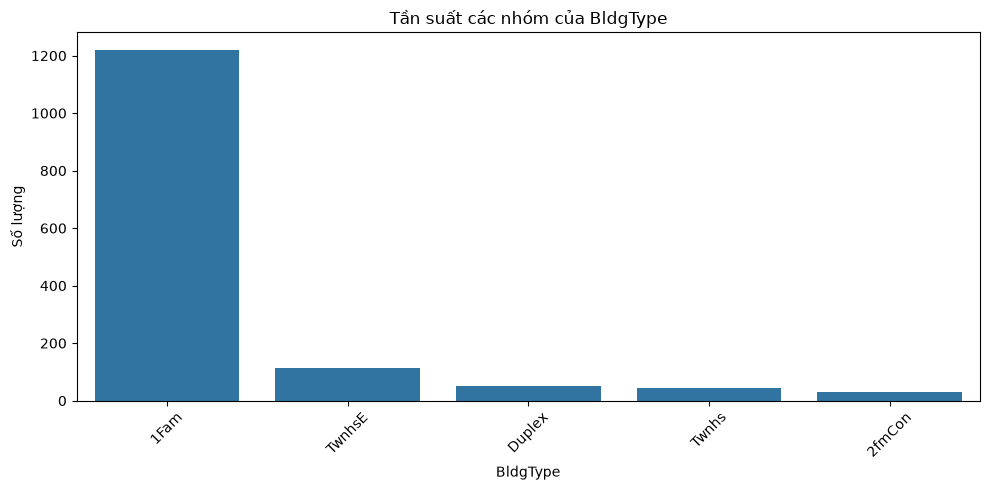

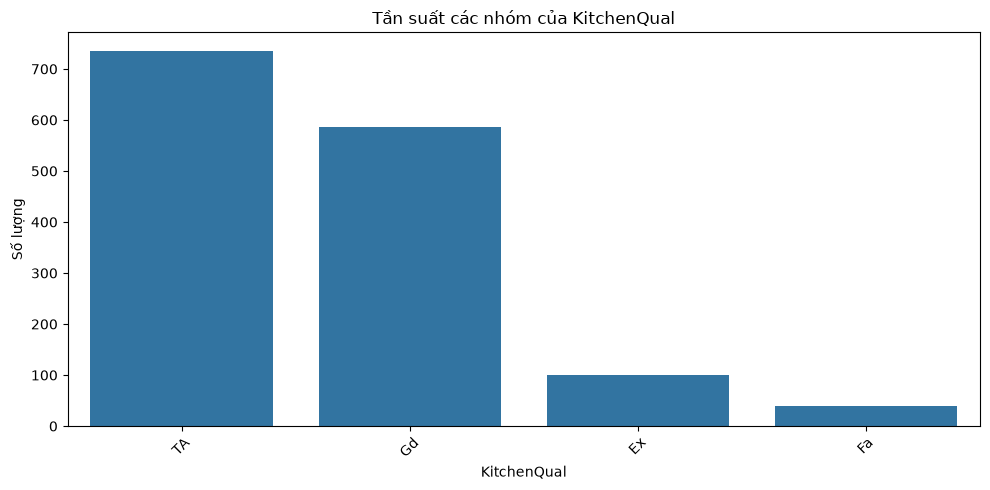

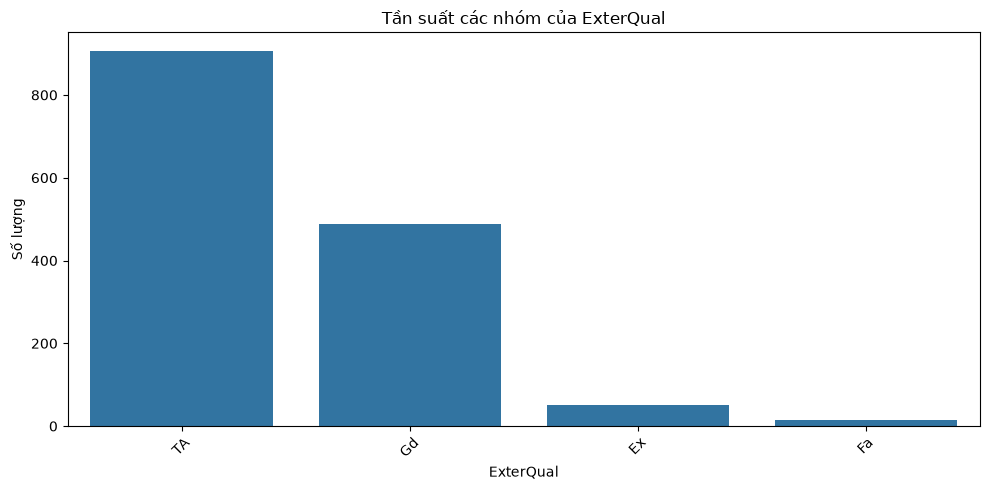

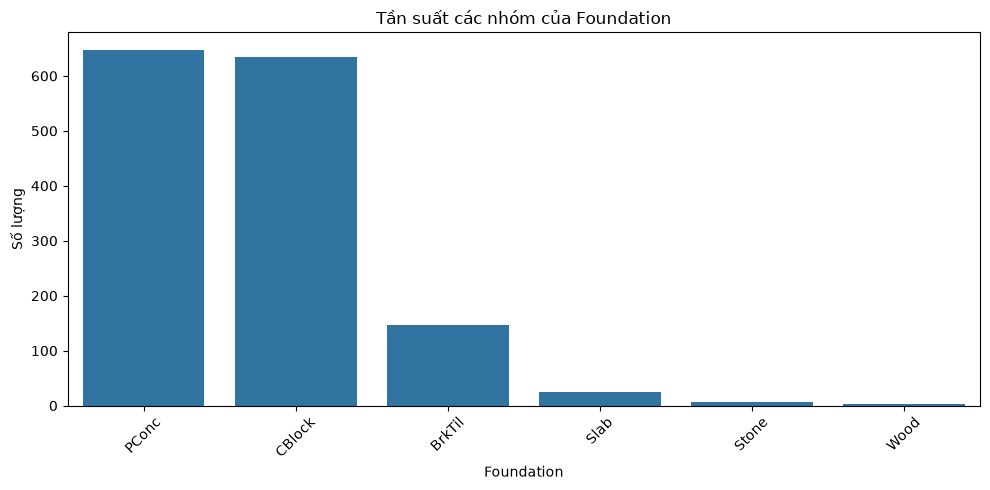

In [59]:
important_categorical = [
    c for c in [
        'Neighborhood', 'HouseStyle', 'BldgType',
        'KitchenQual', 'ExterQual', 'Foundation'
    ] if c in df.columns
]

for col in important_categorical:
    order = df[col].value_counts().index

    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col, order=order)
    plt.title(f'Tần suất các nhóm của {col}')
    plt.xlabel(col)
    plt.ylabel('Số lượng')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 2.6. Tổng hợp kết quả phân tích đơn biến

Từ phân tích đơn biến, có thể ghi nhận:

- `SalePrice` có phân phối lệch phải, cần chú ý khi xây dựng mô hình.
- Một số biến diện tích có nhiều giá trị bằng 0; cần phân biệt đây là **không có đặc trưng đó** hay dữ liệu bị thiếu.
- Một số biến số có độ lệch lớn, cần kiểm tra thêm bằng boxplot và phân tích đa biến.
- Các biến phân loại có số lượng mức khác nhau; một số biến có thể có nhóm rất hiếm.
- `GrLivArea` cần được chú ý khi kiểm tra ngoại lệ. Phần kiểm tra ngoại lệ chi tiết sẽ được thực hiện ở bước tiếp theo, kết hợp với thông tin từ paper của De Cock.
- Phân tích đơn biến mới chỉ mô tả từng biến riêng lẻ; chưa thể kết luận biến nào thực sự ảnh hưởng mạnh đến `SalePrice`. Điều đó cần được kiểm tra ở **phân tích đa biến**.

## 4.1. Giá trị thiếu (Missing values)

### 4.1.1. Thống kê giá trị thiếu

,so_dong_thieu,ty_le_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


19 / 81 cột có giá trị thiếu


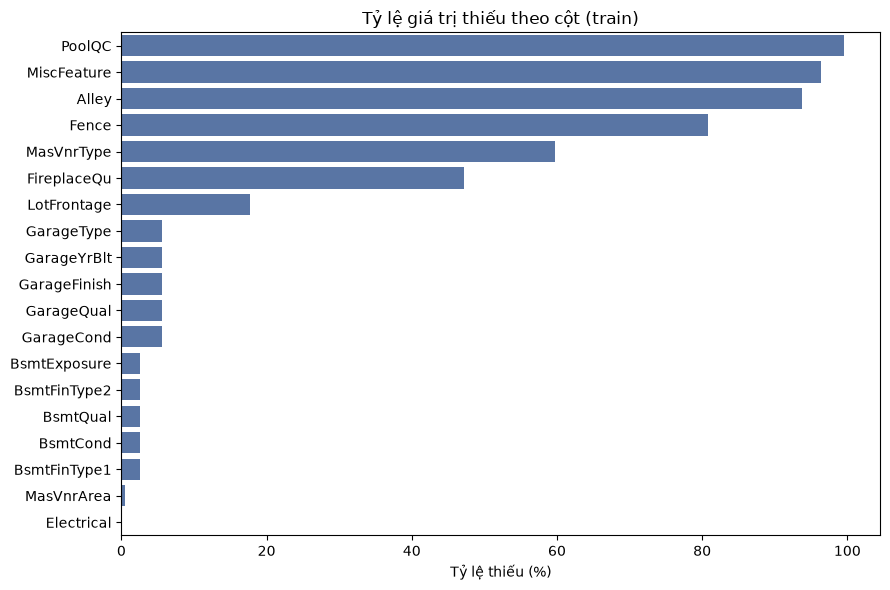

In [60]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)

miss_df = pd.DataFrame({
    'so_dong_thieu': miss,
    'ty_le_%': (miss / len(df) * 100).round(2),
})
display(miss_df)
print(f"{len(miss)} / {df.shape[1]} cột có giá trị thiếu")

plt.figure(figsize=(9, 6))
sns.barplot(x=miss_df['ty_le_%'], y=miss_df.index, color='#4C72B0')
plt.xlabel('Tỷ lệ thiếu (%)'); plt.ylabel('')
plt.title('Tỷ lệ giá trị thiếu theo cột (train)')
plt.tight_layout()
plt.show()

**Nhận xét ban đầu**

- 19 cột có giá trị thiếu. Bốn cột thiếu hơn 80% (`PoolQC`, `MiscFeature`, `Alley`, `Fence`), `MasVnrType` và `FireplaceQu` thiếu gần một nửa hoặc hơn.
- Các cột `Garage*` thiếu cùng một con số (81 dòng) và các cột `Bsmt*` thiếu gần cùng một con số (37-38 dòng). Thiếu **đồng loạt theo nhóm** như vậy là dấu hiệu của thiếu có nguyên nhân, không phải thiếu ngẫu nhiên.
- Trước khi kết luận "dữ liệu bị mất", cần kiểm tra xem `NaN` ở đây thật sự có nghĩa là gì.

### 4.1.2. Cẩn thận: pandas có thể hiểu sai chữ `NA` và `None`

Trong file gốc, chữ `NA` là một nhãn hợp lệ (vd. `Alley = NA` nghĩa là *không có ngõ phụ*) và `None` cũng là nhãn hợp lệ (vd. `MasVnrType = None` nghĩa là *không ốp đá/gạch*). Nhưng `pd.read_csv` mặc định đọc cả hai thành `NaN`. Đọc lại với `keep_default_na=False` để thấy file gốc thực sự chứa gì.

In [61]:
raw = pd.read_csv(r'data/train.csv', keep_default_na=False)

chk = pd.DataFrame({
    'NaN (pandas)'       : df[miss.index].isna().sum(),
    "chữ 'NA' trong file": [(raw[c] == 'NA').sum()   for c in miss.index],
    "chữ 'None' trong file": [(raw[c] == 'None').sum() for c in miss.index],
})
chk

,NaN (pandas),chữ 'NA' trong file,chữ 'None' trong file
PoolQC,1453,1453,0
MiscFeature,1406,1406,0
Alley,1369,1369,0
Fence,1179,1179,0
MasVnrType,872,8,864
FireplaceQu,690,690,0
LotFrontage,259,259,0
GarageType,81,81,0
GarageYrBlt,81,81,0
GarageFinish,81,81,0


**Nhận xét**

- `MasVnrType`: 872 `NaN` thực ra gồm **864 dòng là `None` (nhãn hợp lệ: không ốp)** và chỉ **8 dòng thiếu thật**. Nếu điền theo kiểu "cột này thiếu 60% nên bỏ" thì sẽ mất một biến có thông tin.
- Với `LotFrontage`, `GarageYrBlt`, `MasVnrArea`, `Electrical`, chữ `NA` là **thiếu thật** (cột số hoặc cột không có nhãn "không có").

### 4.1.3. Phân loại: thiếu có cấu trúc hay thiếu thật?

Theo mô tả dữ liệu, với các cột chất lượng/loại của gara, tầng hầm, lò sưởi, hồ bơi, hẻm, hàng rào, `NA` nghĩa là **căn nhà không có đặc trưng đó**. Có thể kiểm chứng giả thuyết này bằng các cột số đi kèm: nếu `PoolQC` là `NaN` thì `PoolArea` phải bằng 0, v.v.

In [62]:
checks = {
    'PoolQC NaN      <-> PoolArea = 0'    : (df['PoolQC'].isna(),      df['PoolArea'] == 0),
    'MiscFeature NaN <-> MiscVal = 0'     : (df['MiscFeature'].isna(), df['MiscVal'] == 0),
    'FireplaceQu NaN <-> Fireplaces = 0'  : (df['FireplaceQu'].isna(), df['Fireplaces'] == 0),
    'GarageType NaN  <-> GarageArea = 0'  : (df['GarageType'].isna(),  df['GarageArea'] == 0),
    'BsmtQual NaN    <-> TotalBsmtSF = 0' : (df['BsmtQual'].isna(),    df['TotalBsmtSF'] == 0),
}
rows = []
for name, (is_nan, is_zero) in checks.items():
    rows.append({'quy tắc': name,
                 'số dòng NaN': int(is_nan.sum()),
                 'khớp với số = 0': int((is_nan & is_zero).sum()),
                 'khớp 100%': bool((is_nan & is_zero).sum() == is_nan.sum())})
display(pd.DataFrame(rows))

g = ['GarageType','GarageYrBlt','GarageFinish','GarageQual','GarageCond']
b = ['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']
print("Số dòng thiếu đồng thời cả 5 cột Garage:", df[g].isna().all(axis=1).sum())
print("Số dòng thiếu đồng thời cả 5 cột Bsmt  :", df[b].isna().all(axis=1).sum())

print("\nHai dòng CÓ tầng hầm nhưng thiếu 1 thuộc tính (thiếu thật):")
display(df.loc[df['BsmtQual'].notna() & df['BsmtExposure'].isna(),  ['Id','BsmtQual','BsmtExposure','TotalBsmtSF']])
display(df.loc[df['BsmtQual'].notna() & df['BsmtFinType2'].isna(), ['Id','BsmtFinType1','BsmtFinType2','BsmtFinSF2']])

,quy tắc,số dòng NaN,khớp với số = 0,khớp 100%
0,PoolQC NaN <-> PoolArea = 0,1453,1453,True
1,MiscFeature NaN <-> MiscVal = 0,1406,1406,True
2,FireplaceQu NaN <-> Fireplaces = 0,690,690,True
3,GarageType NaN <-> GarageArea = 0,81,81,True
4,BsmtQual NaN <-> TotalBsmtSF = 0,37,37,True


Số dòng thiếu đồng thời cả 5 cột Garage: 81
Số dòng thiếu đồng thời cả 5 cột Bsmt  : 37

Hai dòng CÓ tầng hầm nhưng thiếu 1 thuộc tính (thiếu thật):


,Id,BsmtQual,BsmtExposure,TotalBsmtSF
948,949,Gd,NaN,936


,Id,BsmtFinType1,BsmtFinType2,BsmtFinSF2
332,333,GLQ,NaN,479


 **Kết luận phân loại**

Phần lớn dữ liệu thiếu là **thiếu có cấu trúc**, tức là đối tượng **không có đặc trưng đó**, không phải dữ liệu bị mất. Chỉ khoảng **280 ô** là thiếu thật, trong đó **`LotFrontage` chiếm phần lớn**.

- **Thiếu có cấu trúc:** `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, các cột `Garage*`, `Bsmt*` và `MasVnrType = None`.
- **Thiếu thật:** chủ yếu là `LotFrontage` (259 dòng), ngoài ra có một số ít ở `MasVnrType`, `MasVnrArea`, `Electrical`, `BsmtExposure` và `BsmtFinType2`.

> **Kết luận:** Khi tiền xử lý dữ liệu không nên coi tất cả giá trị thiếu là mất dữ liệu; cần phân biệt **“không có đặc trưng”** với **“thực sự không được ghi nhận”**.
### 4.1.4. Cơ chế thiếu của `LotFrontage` (nhóm B lớn nhất)

Để chọn cách điền, cần biết `LotFrontage` thiếu **ngẫu nhiên hoàn toàn (MCAR)** hay thiếu **có liên quan đến các biến khác (MAR)**.

In [63]:
known = df[df['LotFrontage'].notna()].copy()
rng = np.random.RandomState(42)
methods = ['Median toàn cục', 'Median theo Neighborhood',
           'Median theo Neighborhood + LotConfig', 'Hồi quy: √LotArea + Neighborhood']
mae = {m: [] for m in methods}

for _ in range(30):
    idx = rng.choice(known.index, size=int(0.2 * len(known)), replace=False)
    tr, va = known.drop(idx), known.loc[idx]
    g_med = tr['LotFrontage'].median()

    p1 = np.full(len(va), g_med)
    nb = tr.groupby('Neighborhood')['LotFrontage'].median()
    p2 = va['Neighborhood'].map(nb).fillna(g_med).values
    nc = tr.groupby(['Neighborhood', 'LotConfig'])['LotFrontage'].median()
    p3 = np.array([nc.get((a, c), np.nan) for a, c in zip(va['Neighborhood'], va['LotConfig'])])
    p3 = np.where(np.isnan(p3), p2, p3)

    Xtr = pd.get_dummies(tr['Neighborhood']).astype(float); Xtr['sqrtLot'] = np.sqrt(tr['LotArea'])
    Xva = (pd.get_dummies(va['Neighborhood']).reindex(columns=Xtr.columns[:-1], fill_value=0)
             .astype(float)); Xva['sqrtLot'] = np.sqrt(va['LotArea'])
    beta, *_ = np.linalg.lstsq(Xtr.values, tr['LotFrontage'].values, rcond=None)
    p4 = Xva[Xtr.columns].values @ beta

    for m, p in zip(methods, [p1, p2, p3, p4]):
        mae[m].append(np.abs(va['LotFrontage'].values - p).mean())

pd.Series({m: np.mean(v) for m, v in mae.items()}, name='MAE (feet)').round(2).to_frame()

,MAE (feet)
Median toàn cục,16.85
Median theo Neighborhood,13.46
Median theo Neighborhood + LotConfig,12.88
Hồi quy: √LotArea + Neighborhood,12.02


**Nhận xét:** điền theo median của từng `Neighborhood` giảm sai số khoảng 20% so với median toàn cục, và là cách đơn giản, dễ giải thích. Hồi quy theo `√LotArea` + `Neighborhood` còn tốt hơn một chút nhưng phức tạp hơn; có thể dùng nếu muốn tối ưu thêm. Ở đây chọn **median theo `Neighborhood`** (học từ `train`).

**Thí nghiệm chọn cách điền:** che ngẫu nhiên 20% giá trị `LotFrontage` đã biết, điền lại bằng từng cách, đo sai số tuyệt đối trung bình (MAE), lặp 30 lần.

In [64]:
known = df[df['LotFrontage'].notna()].copy()
rng = np.random.RandomState(42)
methods = ['Median toàn cục', 'Median theo Neighborhood',
           'Median theo Neighborhood + LotConfig', 'Hồi quy: √LotArea + Neighborhood']
mae = {m: [] for m in methods}

for _ in range(30):
    idx = rng.choice(known.index, size=int(0.2 * len(known)), replace=False)
    tr, va = known.drop(idx), known.loc[idx]
    g_med = tr['LotFrontage'].median()

    p1 = np.full(len(va), g_med)
    nb = tr.groupby('Neighborhood')['LotFrontage'].median()
    p2 = va['Neighborhood'].map(nb).fillna(g_med).values
    nc = tr.groupby(['Neighborhood', 'LotConfig'])['LotFrontage'].median()
    p3 = np.array([nc.get((a, c), np.nan) for a, c in zip(va['Neighborhood'], va['LotConfig'])])
    p3 = np.where(np.isnan(p3), p2, p3)

    Xtr = pd.get_dummies(tr['Neighborhood']).astype(float); Xtr['sqrtLot'] = np.sqrt(tr['LotArea'])
    Xva = (pd.get_dummies(va['Neighborhood']).reindex(columns=Xtr.columns[:-1], fill_value=0)
             .astype(float)); Xva['sqrtLot'] = np.sqrt(va['LotArea'])
    beta, *_ = np.linalg.lstsq(Xtr.values, tr['LotFrontage'].values, rcond=None)
    p4 = Xva[Xtr.columns].values @ beta

    for m, p in zip(methods, [p1, p2, p3, p4]):
        mae[m].append(np.abs(va['LotFrontage'].values - p).mean())

pd.Series({m: np.mean(v) for m, v in mae.items()}, name='MAE (feet)').round(2).to_frame()

,MAE (feet)
Median toàn cục,16.85
Median theo Neighborhood,13.46
Median theo Neighborhood + LotConfig,12.88
Hồi quy: √LotArea + Neighborhood,12.02


**Nhận xét:** điền theo median của từng `Neighborhood` giảm sai số khoảng 20% so với median toàn cục, và là cách đơn giản, dễ giải thích. Hồi quy theo `√LotArea` + `Neighborhood` còn tốt hơn một chút nhưng phức tạp hơn; có thể dùng nếu muốn tối ưu thêm. Ở đây chọn **median theo `Neighborhood`** (học từ `train`).


## 4.1.5. Hướng giải quyết cho từng nhóm

- `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`: điền `'None'` vì biểu thị **không có đặc trưng**.
- `Garage*`, `Bsmt*`: không có gara/hầm → `'None'`; có nhưng thiếu thuộc tính → **mode**.
- `MasVnrType`: điền `'None'`.
- `MasVnrArea`: điền `0`.
- `GarageYrBlt`: điền bằng `YearBuilt`.
- `LotFrontage`: điền **median theo `Neighborhood`**.
- `Electrical`: điền **mode (`SBrkr`)**.
- Các cột chỉ thiếu ở `test`: cột chữ → **mode**, cột số → **median của `train`**.

### Nguyên tắc chung

- **Xoá dòng:** Không sử dụng.
- **Xoá cột:** Không xoá chỉ vì tỷ lệ thiếu cao.
- **Điền giá trị:** Là hướng xử lý chính, nhưng phải phù hợp với ý nghĩa của từng nhóm dữ liệu.

> **Kết luận:** Cần phân biệt **"không có đặc trưng"** và **"thực sự thiếu dữ liệu"**, sau đó lựa chọn phương pháp xử lý phù hợp.
### 4.1.6. Cài đặt: học tham số từ `train`, áp dụng cho cả `train` và `test`

In [65]:
GARAGE_CAT = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
BSMT_CAT   = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
NONE_CAT   = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'MasVnrType']

def fit_missing_params(train):
    """Học các tham số điền từ TRAIN."""
    has_b = train[BSMT_CAT].notna().any(axis=1)
    has_g = train[GARAGE_CAT].notna().any(axis=1)
    return {
        'lotfront_by_nb': train.groupby('Neighborhood')['LotFrontage'].median(),
        'lotfront_all'  : train['LotFrontage'].median(),
        'bsmt_mode'     : {c: train.loc[has_b, c].mode()[0] for c in BSMT_CAT},
        'garage_mode'   : {c: train.loc[has_g, c].mode()[0] for c in GARAGE_CAT},
        'mode'          : {c: train[c].mode()[0] for c in train.select_dtypes(exclude='number').columns},
        'median'        : train.select_dtypes('number').median(),
    }

def clean_missing(data, p):
    d = data.copy()

    # (1) Thiếu có cấu trúc: không có đặc trưng -> 'None'
    for c in NONE_CAT:
        d[c] = d[c].fillna('None')

    # (2) Hầm / gara: có thì điền mode, không có thì 'None'
    has_bsmt   = d[BSMT_CAT].notna().any(axis=1)
    has_garage = d[GARAGE_CAT].notna().any(axis=1)
    for c in BSMT_CAT:
        d[c] = d[c].fillna(pd.Series(np.where(has_bsmt,   p['bsmt_mode'][c],   'None'), index=d.index))
    for c in GARAGE_CAT:
        d[c] = d[c].fillna(pd.Series(np.where(has_garage, p['garage_mode'][c], 'None'), index=d.index))

    # (3) Biến số của hầm / gara / ốp mặt: không có -> 0
    zero_cols = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
                 'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']
    d[zero_cols] = d[zero_cols].fillna(0)

    # (4) GarageYrBlt là NĂM: không điền 0, dùng năm xây nhà
    d['GarageYrBlt'] = d['GarageYrBlt'].fillna(d['YearBuilt'])

    # (5) LotFrontage: median theo Neighborhood (học từ train)
    d['LotFrontage'] = (d['LotFrontage']
                        .fillna(d['Neighborhood'].map(p['lotfront_by_nb']))
                        .fillna(p['lotfront_all']))

    # (6) Phần còn lại (Electrical, vài cột chỉ thiếu ở test): mode / median của train
    for c in d.columns[d.isna().any()]:
        d[c] = d[c].fillna(p['mode'][c] if c in p['mode'] else p['median'][c])
    return d

params      = fit_missing_params(df)          # chỉ học từ train
train_clean = clean_missing(df,   params)
test_clean  = clean_missing(test, params)

print("Missing còn lại | train:", int(train_clean.isna().sum().sum()), "| test:", int(test_clean.isna().sum().sum()))
print("Số nhà không gara (GarageType='None'):", int((train_clean['GarageType'] == 'None').sum()), "(kỳ vọng 81)")
print("Số nhà không hầm  (BsmtQual='None')  :", int((train_clean['BsmtQual'] == 'None').sum()),  "(kỳ vọng 37)")
print("Shape train/test:", train_clean.shape, test_clean.shape)

Missing còn lại | train: 0 | test: 0
Số nhà không gara (GarageType='None'): 81 (kỳ vọng 81)
Số nhà không hầm  (BsmtQual='None')  : 37 (kỳ vọng 37)
Shape train/test: (1460, 81) (1459, 80)


,trước (chỉ giá trị có sẵn),sau khi điền
count,1201.0,1460.0
mean,70.0,70.2
std,24.3,22.4
min,21.0,21.0
25%,59.0,60.0
50%,69.0,70.0
75%,80.0,80.0
max,313.0,313.0


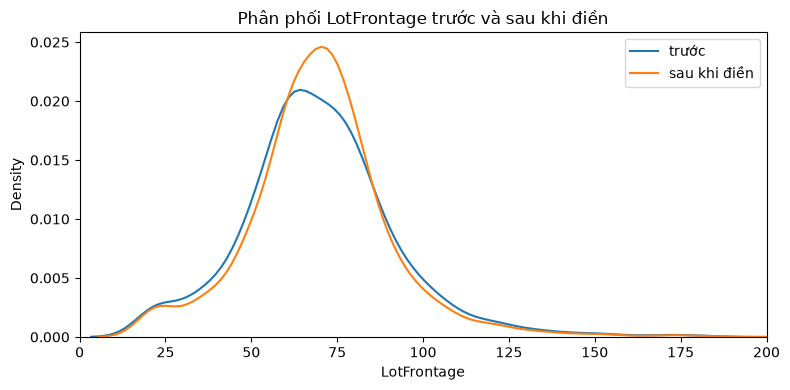

In [71]:
# Kiểm tra: việc điền LotFrontage có làm thay đổi phân phối nhiều không?
cmp = pd.DataFrame({'trước (chỉ giá trị có sẵn)': df['LotFrontage'].describe(),
                    'sau khi điền'               : train_clean['LotFrontage'].describe()}).round(1)
display(cmp)

fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(df['LotFrontage'].dropna(), label='trước', ax=ax)
sns.kdeplot(train_clean['LotFrontage'], label='sau khi điền', ax=ax)
ax.set_xlim(0, 200); ax.set_title('Phân phối LotFrontage trước và sau khi điền'); ax.legend()
plt.tight_layout(); plt.show()

**Nhận xét**

- Phương pháp IQR gắn cờ rất nhiều điểm (vd. `LotArea`, `SalePrice`, `LotFrontage` có khoảng 4-7% số dòng), vì các biến này **lệch phải mạnh**: đuôi dài tự nhiên bị coi là "ngoại lệ". Đây là lý do **không nên xoá mọi điểm bị IQR gắn cờ**.
- Các biến có vài điểm cực lớn tách xa hẳn phần còn lại: `LotArea` (tới 215,245), `TotalBsmtSF` (6,110), `GrLivArea` (5,642), `LotFrontage` (313), `BsmtFinSF1` (5,644). Cần xem các điểm này có phải **cùng một vài căn nhà** hay không.

## 4.2. Ngoại lệ (Outliers)

Ngoại lệ là các đối tượng có giá trị khác biệt đáng kể so với phần lớn dữ liệu. Có hai nguồn gốc rất khác nhau:
- **Ngoại lệ thật**: một căn nhà đặc biệt (biệt thự rất lớn, giá rất cao). Đây là thông tin, không nên xoá bừa.
- **Nhiễu/lỗi**: nhập sai, giao dịch bất thường (không phản ánh quy luật chung). Nên sửa hoặc loại.

Vì vậy, thống kê chỉ giúp **phát hiện ứng viên**; quyết định xử lý phải dựa vào **ý nghĩa nghiệp vụ**.

### 4.2.1. Phát hiện bằng thống kê: IQR và z-score (đơn biến)

- **IQR**: giá trị nằm ngoài `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`.
- **z-score**: `|z| > 3`.
- Với các biến diện tích có nhiều số 0 ("không có"), tính trên **các giá trị > 0** (nếu để cả số 0 thì ngưỡng IQR bị méo).

In [66]:
cont_cols = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF',
             '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF',
             'OpenPorchSF', 'EnclosedPorch', 'ScreenPorch', 'SalePrice']

def outlier_table(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        s = s[s > 0]
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_iqr = int(((s < lo) | (s > hi)).sum())
        n_z   = int((np.abs(stats.zscore(s)) > 3).sum())
        rows.append({'cột': c, 'n (>0)': len(s), 'IQR': n_iqr, '% IQR': round(n_iqr / len(s) * 100, 1),
                     '|z|>3': n_z, 'ngưỡng trên': round(hi, 1), 'max': s.max(), 'skew': round(s.skew(), 2)})
    return pd.DataFrame(rows).set_index('cột')

out_tab = outlier_table(df, cont_cols)
out_tab

,n (>0),IQR,% IQR,|z|>3,ngưỡng trên,max,skew
cột,,,,,,,
LotFrontage,1201,88,7.3,12,111.5,313.0,2.16
LotArea,1460,69,4.7,13,17673.5,215245.0,12.21
MasVnrArea,591,28,4.7,12,656.8,1600.0,2.09
BsmtFinSF1,993,13,1.3,5,1611.0,5644.0,2.30
BsmtUnfSF,1342,30,2.2,11,1676.1,2336.0,0.97
TotalBsmtSF,1423,24,1.7,11,2058.0,6110.0,2.17
1stFlrSF,1460,20,1.4,12,2155.1,4692.0,1.38
2ndFlrSF,631,19,3.0,4,1378.8,2065.0,0.70
GrLivArea,1460,31,2.1,16,2747.6,5642.0,1.37


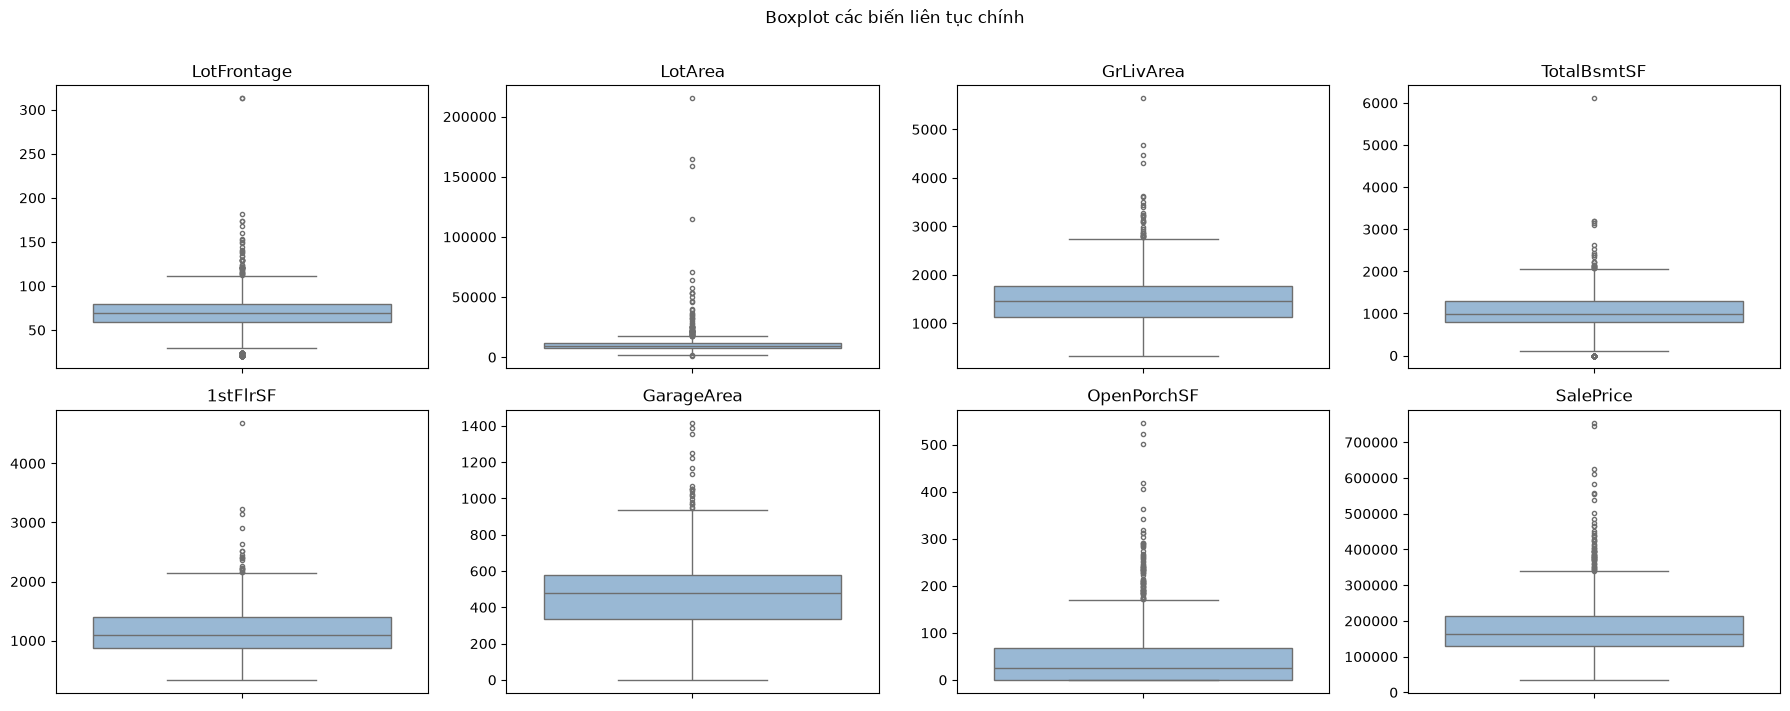

In [67]:
plot_cols = ['LotFrontage', 'LotArea', 'GrLivArea', 'TotalBsmtSF',
             '1stFlrSF', 'GarageArea', 'OpenPorchSF', 'SalePrice']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.boxplot(y=df[c], ax=ax, color='#8FB8DE', fliersize=3)
    ax.set_title(c); ax.set_ylabel('')
plt.suptitle('Boxplot các biến liên tục chính', y=1.01)
plt.tight_layout(); plt.show()

**Nhận xét**

- Phương pháp IQR gắn cờ rất nhiều điểm (vd. `LotArea`, `SalePrice`, `LotFrontage` có khoảng 4-7% số dòng), vì các biến này **lệch phải mạnh**: đuôi dài tự nhiên bị coi là "ngoại lệ". Đây là lý do **không nên xoá mọi điểm bị IQR gắn cờ**.
- Các biến có vài điểm cực lớn tách xa hẳn phần còn lại: `LotArea` (tới 215,245), `TotalBsmtSF` (6,110), `GrLivArea` (5,642), `LotFrontage` (313), `BsmtFinSF1` (5,644). Cần xem các điểm này có phải **cùng một vài căn nhà** hay không.

### 4.2.2. Quan hệ hai biến: ngoại lệ nằm ở đâu so với xu hướng?

Một điểm lớn chưa chắc là xấu: nếu nó **đi theo xu hướng** (nhà lớn thì giá cao) thì là ngoại lệ thật; nếu **đi ngược xu hướng** (nhà rất lớn nhưng giá thấp) thì đáng ngờ. Theo paper của De Cock, nhà có `GrLivArea > 4000` cần được xem xét.

,Id,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleType,SaleCondition,YearBuilt,SalePrice
523,524,4676,3138,40094,10,Edwards,New,Partial,2007,184750
691,692,4316,2444,21535,10,NoRidge,WD,Normal,1994,755000
1182,1183,4476,2396,15623,10,NoRidge,WD,Abnorml,1996,745000
1298,1299,5642,6110,63887,10,Edwards,New,Partial,2008,160000


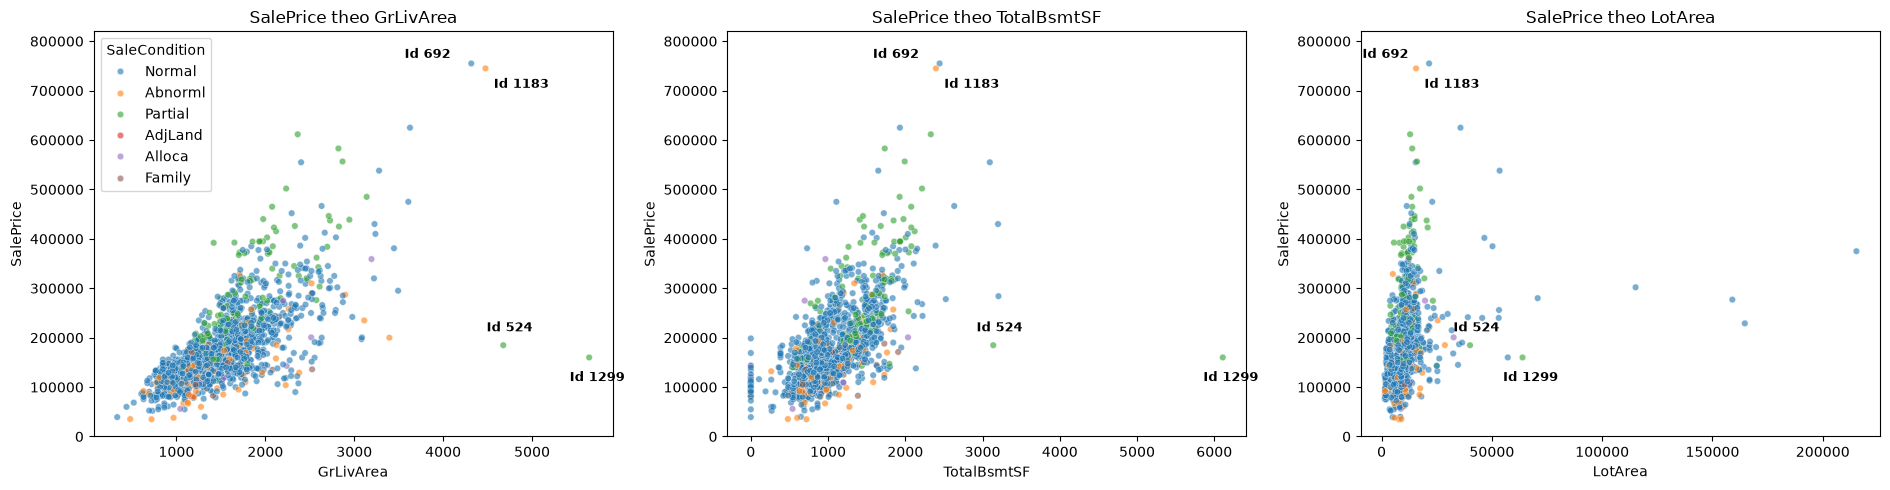

In [68]:
big = df[df['GrLivArea'] > 4000]
display(big[['Id', 'GrLivArea', 'TotalBsmtSF', 'LotArea', 'OverallQual',
             'Neighborhood', 'SaleType', 'SaleCondition', 'YearBuilt', 'SalePrice']])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col in zip(axes, ['GrLivArea', 'TotalBsmtSF', 'LotArea']):
    sns.scatterplot(data=df, x=col, y='SalePrice', hue='SaleCondition', alpha=.6, s=22, ax=ax,
                    legend=(col == 'GrLivArea'))
    offsets = {524: (-12, 10), 1299: (-14, -17), 692: (-48, 4), 1183: (6, -14)}
    for _, r in df[df['Id'].isin(offsets)].iterrows():
        ax.annotate(f"Id {int(r['Id'])}", (r[col], r['SalePrice']), fontsize=9,
                    xytext=offsets[int(r['Id'])], textcoords='offset points', weight='bold')
    ax.set_ylim(0, 820000)
    ax.set_title(f'SalePrice theo {col}')
plt.tight_layout(); plt.show()

## Nhận xét: 4 căn có `GrLivArea > 4000` không giống nhau

- Hai căn **`1299`** và **`524`** đi **ngược xu hướng**: diện tích rất lớn, `OverallQual = 10` nhưng giá chỉ khoảng 160–185 nghìn. Cả hai đều có `SaleCondition = Partial`, nên giá bán có thể không phản ánh đầy đủ giá trị thực của diện tích. Đây là **giao dịch bất thường**.
- Hai căn **`692`** và **`1183`** có diện tích lớn và giá rất cao, **phù hợp với xu hướng chung**. Đây là các ngoại lệ có thể giữ lại vì vẫn mang thông tin hữu ích cho mô hình.

> Không nên áp dụng máy móc quy tắc **"loại bỏ tất cả `GrLivArea > 4000`"**, vì có thể loại nhầm các điểm dữ liệu hợp lệ.

## 4.2.3. Phát hiện ngoại lệ đa biến: Khoảng cách Cook

Khoảng cách Cook đo mức độ **một điểm dữ liệu có khả năng kéo lệch đường hồi quy**.

Mô hình cơ sở sử dụng:

- `log(SalePrice)`
- `log(GrLivArea)`
- `OverallQual`
- `log(LotArea)`
- `log(1 + TotalBsmtSF)`

Cài đặt khoảng cách Cook bằng **`numpy` thuần**.

R² của mô hình cơ sở (giữ toàn bộ): 0.787


,Id,GrLivArea,OverallQual,SalePrice,SaleCondition,stud_resid,cook
1298,1299,5642,10,160000,Partial,-8.146,0.224
523,524,4676,10,184750,Partial,-6.529,0.101
1045,1046,1733,3,139600,Normal,2.389,0.034
705,706,1092,4,55000,Normal,-2.097,0.022
495,496,720,4,34900,Abnorml,-5.159,0.021
30,31,1317,4,40000,Normal,-5.592,0.018
457,458,1663,4,256000,Normal,2.581,0.017
968,969,968,3,37900,Abnorml,-4.129,0.016


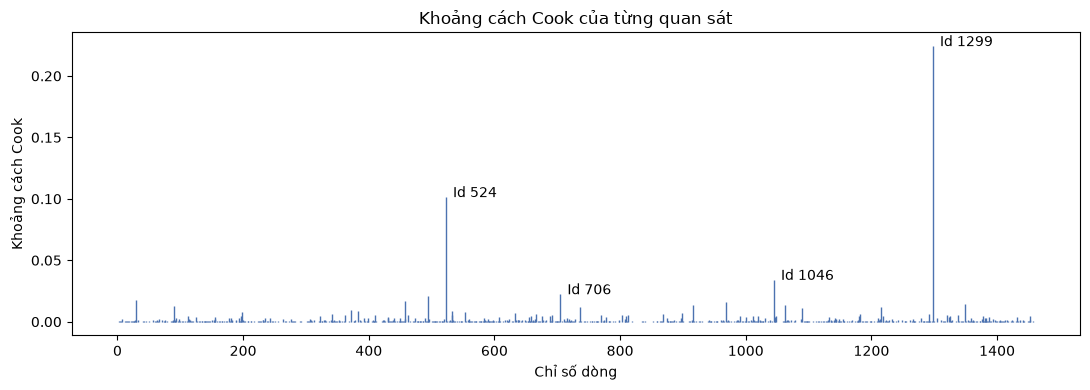

In [69]:
def ols_diagnostics(data):
    X = np.column_stack([np.ones(len(data)), np.log(data['GrLivArea']), data['OverallQual'],
                         np.log(data['LotArea']), np.log1p(data['TotalBsmtSF'])])
    y = np.log(data['SalePrice'].values)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    n, p = X.shape
    h = np.einsum('ij,jk,ik->i', X, np.linalg.inv(X.T @ X), X)        # đòn bẩy (leverage)
    s2 = res @ res / (n - p)
    stud = res / np.sqrt(s2 * (1 - h))                                  # phần dư chuẩn hóa
    cook = (res ** 2 / (p * s2)) * (h / (1 - h) ** 2)                   # khoảng cách Cook
    r2 = 1 - (res @ res) / ((y - y.mean()) @ (y - y.mean()))
    return r2, stud, cook

r2_all, stud, cook = ols_diagnostics(df)
diag = df.assign(stud_resid=stud, cook=cook)
print(f"R² của mô hình cơ sở (giữ toàn bộ): {r2_all:.3f}")
top = diag.nlargest(8, 'cook')[['Id', 'GrLivArea', 'OverallQual', 'SalePrice', 'SaleCondition', 'stud_resid', 'cook']].round(3)
display(top)

plt.figure(figsize=(11, 4))
plt.vlines(diag.index, 0, diag['cook'], color='#4C72B0', lw=1)
for _, r in diag.nlargest(4, 'cook').iterrows():
    plt.annotate(f"Id {int(r['Id'])}", (r.name, r['cook']), xytext=(5, 0), textcoords='offset points')
plt.xlabel('Chỉ số dòng'); plt.ylabel("Khoảng cách Cook"); plt.title("Khoảng cách Cook của từng quan sát")
plt.tight_layout(); plt.show()

**Nhận xét:** hai điểm **Id 1299** (Cook ≈ 0.22) và **Id 524** (Cook ≈ 0.10) vượt xa tất cả các điểm còn lại (điểm lớn thứ ba chỉ khoảng 0.03) và có phần dư chuẩn hóa rất âm (khoảng -8.1 và -6.5): mô hình dự đoán giá cao hơn nhiều so với giá thực. Phương pháp đa biến **xác nhận độc lập** kết luận ở 4.2.2. Hai biệt thự 692 và 1183 **không** nằm trong nhóm này vì chúng đi đúng xu hướng.

Một số nhà giá rất thấp so với chất lượng (vd. Id 31, 496) cũng có phần dư lớn nhưng ảnh hưởng (Cook) nhỏ; đó là các nhà chất lượng thấp bán giá rất thấp, không có đòn bẩy lớn để kéo lệch mô hình, nên **giữ lại**.

### 4.2.4. Kiểm tra lỗi logic dữ liệu

In [72]:
logic = {
    'YearRemodAdd < YearBuilt (sửa trước khi xây)': int((df['YearRemodAdd'] < df['YearBuilt']).sum()),
    'YrSold < YearBuilt (bán trước khi xây)'       : int((df['YrSold'] < df['YearBuilt']).sum()),
    'GarageYrBlt > YrSold (gara xây sau khi bán)'  : int((df['GarageYrBlt'] > df['YrSold']).sum()),
    'GrLivArea != 1stFlr + 2ndFlr + LowQualFin'    : int((df['GrLivArea'] != df['1stFlrSF'] + df['2ndFlrSF'] + df['LowQualFinSF']).sum()),
    'TotalBsmtSF != BsmtFin1 + BsmtFin2 + BsmtUnf' : int((df['TotalBsmtSF'] != df['BsmtFinSF1'] + df['BsmtFinSF2'] + df['BsmtUnfSF']).sum()),
    'MasVnrType = None nhưng MasVnrArea > 0'        : int(((raw['MasVnrType'] == 'None') & (df['MasVnrArea'] > 0)).sum()),
    'GarageYrBlt < YearBuilt (gara có trước nhà)'  : int((df['GarageYrBlt'] < df['YearBuilt']).sum()),
}
print("TRAIN")
display(pd.Series(logic, name='số dòng vi phạm').to_frame())
print("TEST: GarageYrBlt > YrSold")
display(test.loc[test['GarageYrBlt'] > test['YrSold'], ['Id', 'YearBuilt', 'GarageYrBlt', 'YrSold']])
print("Giao dịch trong dữ liệu kéo dài từ", test['YrSold'].min(), "đến", test['YrSold'].max(),
      "-> mọi năm xây dựng phải <=", test['YrSold'].max())

TRAIN


,số dòng vi phạm
YearRemodAdd < YearBuilt (sửa trước khi xây),0
YrSold < YearBuilt (bán trước khi xây),0
GarageYrBlt > YrSold (gara xây sau khi bán),0
GrLivArea != 1stFlr + 2ndFlr + LowQualFin,0
TotalBsmtSF != BsmtFin1 + BsmtFin2 + BsmtUnf,0
MasVnrType = None nhưng MasVnrArea > 0,5
GarageYrBlt < YearBuilt (gara có trước nhà),9


TEST: GarageYrBlt > YrSold


,Id,YearBuilt,GarageYrBlt,YrSold
1089,2550,2008,2008.0,2007
1132,2593,2006,2207.0,2007


Giao dịch trong dữ liệu kéo dài từ 2006 đến 2010 -> mọi năm xây dựng phải <= 2010


## Nhận xét

- Các ràng buộc cộng diện tích (`GrLivArea`, `TotalBsmtSF`) và thứ tự thời gian đều **khớp 100%** trên `train`: dữ liệu rất sạch về logic.
- 9 dòng có `GarageYrBlt < YearBuilt` là hợp lý (gara có từ trước khi nhà được xây lại), **không phải lỗi**.
- 5 dòng `MasVnrType = None` nhưng `MasVnrArea > 0` (có 2 dòng chỉ bằng 1 sq ft) là sai lệch nhỏ, ảnh hưởng không đáng kể nên chỉ ghi nhận.
- Trên `test` có 2 dòng `GarageYrBlt > YrSold`, nhưng chỉ **một dòng là lỗi**:
  - **Id 2593**: `GarageYrBlt = 2207` (nhà xây 2006, bán 2007) là năm không thể có, nhiều khả năng gõ nhầm của 2007. Phải sửa vì một năm trong tương lai sẽ làm méo mọi đặc trưng tuổi gara.
  - **Id 2550**: nhà xây 2008 nhưng bán 2007, gara cùng năm với nhà. Đây là trường hợp bán khi nhà chưa hoàn thiện (xem `SaleCondition = Partial`), **hợp lý, giữ nguyên**.

## 4.2.5. Hướng giải quyết cho ngoại lệ

- **Id 524, 1299** (rất lớn, `Partial`, giá thấp bất thường)
  - **Quyết định:** **Xoá khỏi `train`**.
  - **Lý do:** Là giao dịch bất thường, đi ngược xu hướng, ảnh hưởng (Cook) cao gấp 3–7 lần các điểm khác; kéo giảm tương quan `GrLivArea`–`SalePrice`.

- **Id 692, 1183** (nhà lớn, giá cao, đúng xu hướng)
  - **Quyết định:** **Giữ**.
  - **Lý do:** Ngoại lệ thật; mô hình cần học được vùng giá cao.

- **Các điểm bị IQR gắn cờ do đuôi lệch phải (`LotArea`, `SalePrice`, `OpenPorchSF`...)
  - **Quyết định:** **Giữ**, xử lý bằng **biến đổi log** (`log1p`).
  - **Lý do:** Là đặc tính của phân phối, không phải lỗi. Log làm giảm tác động của đuôi.

- **Lỗi nhập liệu `GarageYrBlt = 2207` ở `test` (Id 2593)**
  - **Quyết định:** **Sửa** (thay bằng `YearBuilt`; hoặc 2007 nếu cho đó là gõ nhầm).
  - **Lý do:** Lỗi rõ ràng, không thể xoá dòng của `test`.

- **Mô hình nhạy với ngoại lệ (hồi quy tuyến tính, Ridge/Lasso, KNN)**
  - **Quyết định:** Thêm **cắt ngưỡng (winsorize) 1%–99%** học từ `train`, hoặc dùng `RobustScaler`, `HuberRegressor`.
  - **Lý do:** Hạn chế ảnh hưởng của vài điểm cực lớn mà không mất dòng nào.

- **Mô hình cây (Random Forest, Gradient Boosting)**
  - **Quyết định:** Gần như không cần xử lý thêm.
  - **Lý do:** Cây chia theo ngưỡng, ít nhạy với giá trị cực lớn.

> **Lưu ý:** `test` có nhà `GrLivArea = 5095` (lớn hơn mọi nhà trong `train` ngoại trừ Id 1299). Không được xoá dòng của `test`, nên mô hình phải đủ bền vững với giá trị lớn (vì thế nên dùng log hoặc cắt ngưỡng bằng giá trị học từ `train`).

In [73]:
# (a) Xoá 2 giao dịch bất thường khỏi train
OUTLIER_IDS = [524, 1299]
train_clean = train_clean[~train_clean['Id'].isin(OUTLIER_IDS)].reset_index(drop=True)

# (b) Sửa lỗi nhập liệu ở test: năm xây gara vượt quá thời gian của dữ liệu (2006-2010)
bad = test_clean['GarageYrBlt'] > test_clean['YrSold'].max()
print("Dòng test sửa:", test_clean.loc[bad, ['Id', 'YearBuilt', 'GarageYrBlt', 'YrSold']].to_dict('records'))
test_clean.loc[bad, 'GarageYrBlt'] = test_clean.loc[bad, 'YearBuilt']

print("train_clean:", train_clean.shape, "| test_clean:", test_clean.shape)

Dòng test sửa: [{'Id': 2593, 'YearBuilt': 2006, 'GarageYrBlt': 2207.0, 'YrSold': 2007}]
train_clean: (1458, 81) | test_clean: (1459, 80)


#### Kiểm chứng quyết định: chỉ xoá 2 điểm là đủ?

So sánh ba phương án trên cùng mô hình cơ sở: giữ hết, xoá 2 điểm (524, 1299), xoá cả 4 điểm `GrLivArea > 4000` (theo quy tắc của paper).

In [74]:
scen = {
    'Giữ nguyên (1460 dòng)'                        : df,
    'Xoá Id 524, 1299 (1458 dòng)  <- chọn'         : df[~df['Id'].isin([524, 1299])],
    'Xoá cả 4 điểm GrLivArea > 4000 (1456 dòng)'    : df[df['GrLivArea'] <= 4000],
}
rows = []
for name, d in scen.items():
    r2, _, ck = ols_diagnostics(d)
    rows.append({'phương án': name,
                 'corr(GrLivArea, SalePrice)': round(d['GrLivArea'].corr(d['SalePrice']), 3),
                 'R² mô hình cơ sở': round(r2, 3),
                 'Cook lớn nhất': round(ck.max(), 3)})
pd.DataFrame(rows).set_index('phương án')

,"corr(GrLivArea, SalePrice)",R² mô hình cơ sở,Cook lớn nhất
phương án,,,
Giữ nguyên (1460 dòng),0.709,0.787,0.224
"Xoá Id 524, 1299 (1458 dòng) <- chọn",0.735,0.803,0.037
Xoá cả 4 điểm GrLivArea > 4000 (1456 dòng),0.721,0.800,0.037


**Nhận xét:** xoá đúng 2 điểm bất thường làm tương quan `GrLivArea`-`SalePrice` tăng rõ (0.709 → 0.735) và R² tăng, Cook lớn nhất giảm mạnh. Xoá cả 4 điểm cho kết quả **kém hơn một chút** (tương quan 0.721; R² 0.800 so với 0.803) vì loại nhầm 2 biệt thự đúng xu hướng. Chênh lệch R² nhỏ, nhưng quan trọng hơn là xoá 2 điểm hợp lệ làm mất thông tin về nhóm nhà giá cao nhất.

Ngoài ra, chỉ 2 dòng này đã chi phối độ lệch: sau khi xoá, `skew` của `GrLivArea` giảm từ 1.37 xuống 1.01 và của `TotalBsmtSF` từ 1.52 xuống 0.51 (xem bảng ở 4.2.6). Vậy quy tắc "bỏ `GrLivArea > 4000`" của paper được áp dụng cho bộ dữ liệu đầy đủ 2930 dòng, còn trên `train.csv` này cần kiểm tra từng điểm như trên.

### 4.2.6. Biến đổi log và cắt ngưỡng cho phần đuôi lệch

Với các điểm "ngoại lệ thật" được giữ lại, có hai công cụ giảm ảnh hưởng của đuôi dài mà không mất dòng nào. Ngưỡng cắt phải **học từ `train`**.

In [75]:
def fit_clip(train, cols, lo=0.01, hi=0.99):
    return {c: (train[c].quantile(lo), train[c].quantile(hi)) for c in cols}

def apply_clip(data, bounds):
    d = data.copy()
    for c, (a, b) in bounds.items():
        d[c] = d[c].clip(a, b)
    return d

clip_cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'SalePrice']
bounds = fit_clip(train_clean, clip_cols)

skew_tab = pd.DataFrame({
    'skew gốc'            : train_clean[clip_cols].skew(),
    'skew sau cắt 1%-99%' : apply_clip(train_clean, bounds)[clip_cols].skew(),
    'skew sau log1p'      : np.log1p(train_clean[clip_cols]).skew(),
}).round(2)
display(skew_tab)

,skew gốc,skew sau cắt 1%-99%,skew sau log1p
LotArea,12.57,2.20,-0.18
GrLivArea,1.01,0.77,-0.07
TotalBsmtSF,0.51,0.22,-5.17
SalePrice,1.88,1.27,0.12


**Nhận xét**

- `log1p` đưa `SalePrice`, `LotArea`, `GrLivArea` về gần đối xứng (skew xấp xỉ 0): đây là cách xử lý đuôi hiệu quả nhất cho các biến này. Với biến mục tiêu `SalePrice`, nên huấn luyện trên `log1p(SalePrice)` rồi đổi ngược bằng `np.expm1` khi dự đoán.
- **Cẩn thận với `TotalBsmtSF`**: biến này có nhiều giá trị 0 (nhà không có hầm), `log1p` biến chúng thành 0 trong khi các giá trị còn lại khoảng 6-8, tạo skew rất âm (khoảng -5). Với biến nhiều số 0 nên dùng cờ `HasBsmt` + log của phần > 0, hoặc chỉ cắt ngưỡng, không log thẳng.
- Cắt ngưỡng 1%-99% giảm skew ít hơn log nhưng giữ nguyên thang đo gốc, hữu ích khi cần giải thích hệ số.

## 4.3. Tổng kết Phần 4

**Giá trị thiếu**
- 19 cột có `NaN`, nhưng phần lớn là **"không có đặc trưng"** (hồ bơi, hẻm, hàng rào, lò sưởi, gara, tầng hầm), đã kiểm chứng với các cột số đi kèm. Chỉ khoảng 280 ô là thiếu thật, chủ yếu `LotFrontage`.
- Cẩn thận `pd.read_csv` đọc nhãn hợp lệ `NA`/`None` thành `NaN` (ví dụ `MasVnrType`: 864 trong 872 dòng là `None` hợp lệ).
- Xử lý: điền `'None'` cho thiếu có cấu trúc, `0` cho diện tích tương ứng, `YearBuilt` cho `GarageYrBlt`, median theo `Neighborhood` cho `LotFrontage` (thí nghiệm cho sai số thấp hơn median toàn cục), mode cho `Electrical`. **Không xoá dòng, không xoá cột** chỉ vì thiếu.

**Ngoại lệ**
- IQR gắn cờ nhiều điểm do phân phối lệch phải; chỉ coi là **ứng viên**.
- Kết hợp quan hệ hai biến, khoảng cách Cook và `SaleCondition` xác định đúng **2 giao dịch bất thường (Id 524, 1299)** → xoá khỏi `train`. Hai biệt thự `GrLivArea > 4000` còn lại (692, 1183) đúng xu hướng → giữ.
- Đuôi lệch còn lại xử lý bằng `log1p` (hoặc cắt ngưỡng học từ `train` nếu mô hình nhạy ngoại lệ); sửa lỗi nhập liệu `GarageYrBlt = 2207` ở `test`.

**Quy trình khi mô hình hóa:** học tham số (median, mode, ngưỡng cắt) từ `train` → áp dụng cho `train` và `test` → chỉ xoá dòng ở `train`, không xoá dòng ở `test`.

Dữ liệu đã làm sạch: `train_clean`, `test_clean` (dùng cho các phần tiếp theo).